# Proyek Klasifikasi Gambar: [Input Nama Dataset]
- **Nama:** Muhammad Alif Rijaluddin Yusufi
- **Email:** m.alifrijal56@gmail.com
- **ID Dicoding:** alifrijal

## Import Semua Packages/Library yang Digunakan

In [1]:
!pip install split-folders

In [2]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from pathlib import Path
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import Callback, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import splitfolders
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Preparation

#### Split & Load Dataset

In [3]:
input_path = '/content/drive/MyDrive/dataset'
output_path = '/content/drive/MyDrive/dataset_split'
train_path = '/content/drive/MyDrive/dataset_split/train'
val_path = '/content/drive/MyDrive/dataset_split/val'
test_path = '/content/drive/MyDrive/dataset_split/test'
items = os.listdir(input_path)
print(items)

splitfolders.ratio(input_path, output=output_path, seed=42, ratio=(.8,.1,.1), group_prefix=None)
items_splitting = os.listdir(output_path)
items_splitting
itemst = os.listdir(train_path)
itemst

train_dir = []
test_dir = []
validation_dir = []
for item in items :
  train_dir.append(train_path + '/' + item + '/')
  validation_dir.append(val_path + '/' + item + '/')
  test_dir.append(test_path + '/' + item + '/')

['forest', 'buildings', 'glacier', 'mountain', 'street', 'sea']


Copying files: 16901 files [08:33, 32.90 files/s]


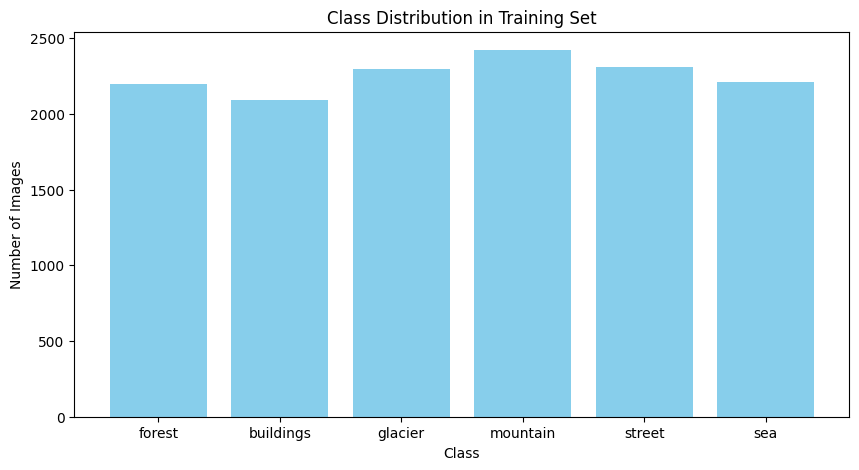

In [4]:
class_names = [
    folder for folder in os.listdir(input_path)
    if os.path.isdir(os.path.join(input_path, folder))
    and folder not in ['train', 'val', 'test']
]

img_format = ('jpg', 'jpeg', 'png', 'bmp', 'webp')
class_counts = []
for class_name in class_names:
  class_dir = os.path.join(train_path, class_name)
  if os.path.exists(class_dir):
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(img_format)]
    class_counts.append(len(files))
  else:
    class_counts.append(0)

plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts, color='skyblue')
plt.title("Class Distribution in Training Set")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [5]:
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0

    for subdir in os.listdir(directory):
        subdir_path = os.path.join(directory, subdir)
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images}")
        total_images += num_images

        for img_file in image_files:
            img_path = os.path.join(subdir_path, img_file)
            with Image.open(img_path) as img:
                unique_sizes.add(img.size)

        for size in unique_sizes:
            print(f"- {size}")
        print("---------------")

    print(f"\nTotal: {total_images}")

print_images_resolution(train_path)
print_images_resolution(val_path)
print_images_resolution(test_path)

forest: 2196
- (150, 136)
- (150, 113)
- (150, 135)
- (150, 115)
- (150, 150)
- (150, 108)
- (150, 133)
---------------
buildings: 2088
- (150, 136)
- (150, 113)
- (150, 135)
- (150, 115)
- (150, 150)
- (150, 124)
- (150, 108)
- (150, 133)
---------------
glacier: 2299
- (150, 136)
- (150, 142)
- (150, 102)
- (150, 108)
- (150, 111)
- (150, 120)
- (150, 123)
- (150, 135)
- (150, 150)
- (150, 110)
- (150, 113)
- (150, 76)
- (150, 134)
- (150, 143)
- (150, 146)
- (150, 97)
- (150, 115)
- (150, 124)
- (150, 133)
- (150, 72)
---------------
mountain: 2421
- (150, 136)
- (150, 81)
- (150, 145)
- (150, 142)
- (150, 102)
- (150, 108)
- (150, 111)
- (150, 120)
- (150, 123)
- (150, 135)
- (150, 141)
- (150, 144)
- (150, 150)
- (150, 147)
- (150, 110)
- (150, 113)
- (150, 131)
- (150, 76)
- (150, 134)
- (150, 143)
- (150, 146)
- (150, 100)
- (150, 97)
- (150, 103)
- (150, 115)
- (150, 124)
- (150, 133)
- (150, 72)
---------------
street: 2306
- (150, 136)
- (150, 81)
- (150, 145)
- (150, 142)
- 

In [6]:
img_size = (224, 224)
batch_size = 32

train = tf.keras.utils.image_dataset_from_directory(
  train_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=True,
)

val = tf.keras.utils.image_dataset_from_directory(
  val_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=False,
)

test = tf.keras.utils.image_dataset_from_directory(
  test_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=False,
)

Found 13519 files belonging to 6 classes.
Found 1688 files belonging to 6 classes.
Found 1694 files belonging to 6 classes.


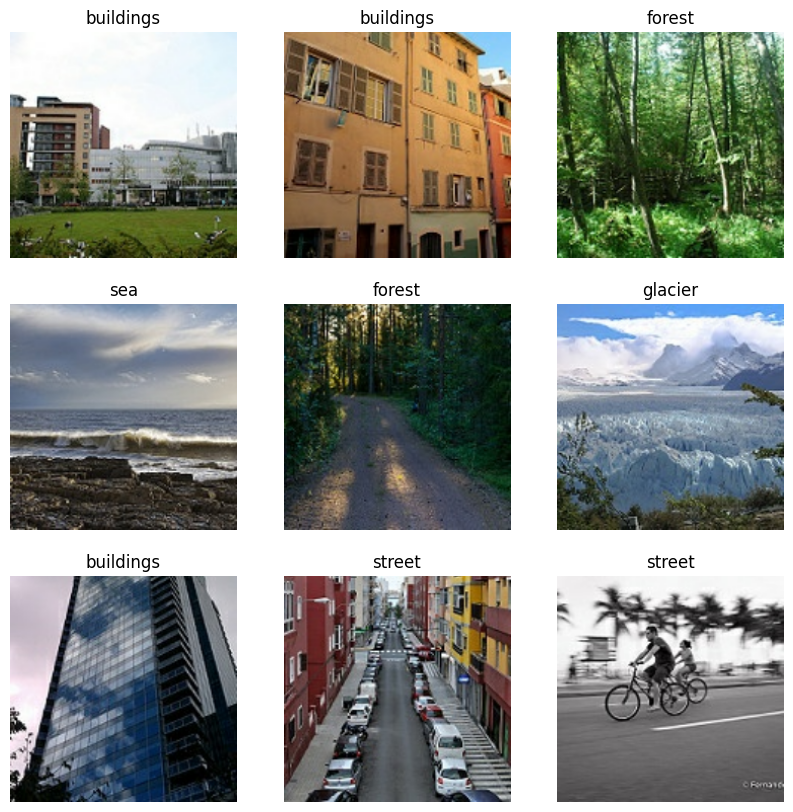

In [7]:
plt.figure(figsize=(10, 10))
for images, labels in train.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(train.class_names[labels[i]])
        plt.axis('off')
plt.show()

### Data Preprocessing

In [8]:
train_norm = train.map(lambda x, y: (x / 255.0, y))
val_norm = val.map(lambda x, y: (x / 255.0, y))
test_norm = test.map(lambda x, y: (x / 255.0, y))

num_classes = len(class_names)

for gambar, label in train_norm.take(1):
  print("Shape gambar:", gambar.shape)
  print("Shape label:", label.shape)
  print("Nilai piksel minimum:", tf.reduce_min(gambar).numpy())
  print("Nilai piksel maksimum:", tf.reduce_max(gambar).numpy())

Shape gambar: (32, 224, 224, 3)
Shape label: (32,)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 1.0


## Modelling

In [16]:
data_aug = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

model = Sequential([
    layers.Input(img_size + (3,)),
    data_aug,

    layers.Conv2D(32, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,878 (1.49 MB)

 Trainable params: 390,918 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
model.compile(
  optimizer=Adam(),
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy']
)

stop = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
    ]

history = model.fit(
  train_norm,
  validation_data=val_norm,
  epochs=50,
  batch_size=batch_size,
  callbacks=stop,
  verbose=1
)

loss, accuracy = model.evaluate(test_norm)

Epoch 1/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 57s 127ms/step - accuracy: 0.6435 - loss: 0.9281 - val_accuracy: 0.3768 - val_loss: 2.0079 - learning_rate: 0.0010
Epoch 2/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 54s 129ms/step - accuracy: 0.7640 - loss: 0.6296 - val_accuracy: 0.6872 - val_loss: 0.8158 - learning_rate: 0.0010
Epoch 3/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 55s 129ms/step - accuracy: 0.8115 - loss: 0.5151 - val_accuracy: 0.7488 - val_loss: 0.6812 - learning_rate: 0.0010
Epoch 4/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 55s 130ms/step - accuracy: 0.8347 - loss: 0.4559 - val_accuracy: 0.7269 - val_loss: 0.7057 - learning_rate: 0.0010
Epoch 5/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 58s 136ms/step - accuracy: 0.8471 - loss: 0.4214 - val_accuracy: 0.8329 - val_loss: 0.4360 - learning_rate: 0.0010
Epoch 6/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 79s 129ms/step - accuracy: 0.8602 - loss: 0.3931 - val_accuracy: 0.7802 - val_loss: 0.5689 - learning_rate: 0.0010
Epoch 7/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 55s 130ms/step - accuracy: 0.8

## Evaluasi dan Visualisasi

In [ ]:
# Plot Akurasi
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Train', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val', linewidth=2)
plt.title('Plot Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train', linewidth=2)
plt.plot(history.history['val_loss'], label='Val', linewidth=2)
plt.title('Plot Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f'\nAccuracy: {accuracy * 100:.2f}%')

In [ ]:
x_test_list = []
y_test_list = []

for images, labels in test_norm:
    x_test_list.append(images.numpy())
    y_test_list.append(labels.numpy())

x_test = np.concatenate(x_test_list, axis=0)
y_true_classes = np.concatenate(y_test_list, axis=0)

y_pred_probs = model.predict(test_norm)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(10, 10))
for i in range(16):
    index = np.random.randint(0, len(x_test))
    plt.subplot(4, 4, i + 1)

    plt.imshow(x_test[index])

    true_label = train.class_names[y_true_classes[index]]
    pred_label = train.class_names[y_pred_classes[index]]
    color = 'green' if true_label == pred_label else 'red'

    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=8)
    plt.axis("off")

plt.suptitle("Sample Predictions (Green = Correct, Red = Incorrect)", fontsize=14)
plt.show()

## Konversi Model

In [ ]:
# # Model -> Saved_Model
# os.mkdirs('/content/drive/MyDrive/Saved_Model', exist_ok=True)
# sm_path = '/content/drive/MyDrive/Saved_model'

# sm_export = Sequential([
#     layers.Input(img_size + (3,)),
#     *[l for l model.layers if l is not data_aug],
# ])

# sm_export.export(sm_path)
# print(f'\nModel saved to: {sm_path}')

In [ ]:
# # Convert Saved Model -> TFLite
# os.mkdirs('/content/drive/MyDrive/TFL', exist_ok=True)
# tfl_path = '/content/drive/MyDrive/TFL'

# tfl_converter = tf.lite.TFLiteConverter.from_saved_model(sm_path)
# tfl_model = tfl_converter.convert()
# with open(tfl_path, 'wb') as f:
#   f.write(tfl_model)
# print(f'\nModel saved to: {tfl_path}')

In [ ]:
# # Convert Saved_Model -> TFJS
# os.mkdirs('/content/drive/MyDrive/TFJS', exist_ok=True)
# tfjs_path = '/content/drive/MyDrive/TFJS'

# !tensorflowjs_converter --input_format=tf_saved_model {sm_path} {tfjs_path}
# print(f'\nModel saved to: {tfjs_path}')

## Inference (Optional)